# CS5812 – Predictive Data Analysis
## Smart Meters in London – Half-Hourly Load Prediction

**Research Question:**  
> Can we accurately predict household half-hourly electricity consumption (kWh) using time-of-day, weekend/holiday indicators, outdoor temperature, tariff type, and ACORN socio-demographic group — and does model performance differ across customer segments?

**Datasets used:**
- `halfhourly_dataset/block_*.csv` – half-hourly energy readings per household
- `informations_households.csv` – household metadata (ACORN, tariff)
- `weather_hourly_darksky.csv` – hourly weather (temperature, humidity, wind, etc.)
- `uk_bank_holidays.csv` – UK bank holidays

**Target variable:** `energy(kWh/hh)` – energy consumed in each 30-minute slot

---
## 0. Imports and Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ── Reproducibility ──────────────────────────────────────────────────────────
RNG_SEED = 42
np.random.seed(RNG_SEED)

# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_DIR = Path("data")

# ── Plot style ────────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120

print("Setup complete.")

Setup complete.


---
## 1. Load Household Metadata

In [2]:
info_df = pd.read_csv(DATA_DIR / "informations_households.csv", encoding="latin1")
print(f"Households: {len(info_df):,}")
print(info_df.head())
print("\nTariff distribution:")
print(info_df["stdorToU"].value_counts())
print("\nACORN_grouped distribution:")
print(info_df["Acorn_grouped"].value_counts())

Households: 5,566
       LCLid stdorToU    Acorn Acorn_grouped     file
0  MAC005492      ToU   ACORN-        ACORN-  block_0
1  MAC001074      ToU   ACORN-        ACORN-  block_0
2  MAC000002      Std  ACORN-A      Affluent  block_0
3  MAC003613      Std  ACORN-A      Affluent  block_0
4  MAC003597      Std  ACORN-A      Affluent  block_0

Tariff distribution:
stdorToU
Std    4443
ToU    1123
Name: count, dtype: int64

ACORN_grouped distribution:
Acorn_grouped
Affluent       2192
Adversity      1816
Comfortable    1507
ACORN-U          49
ACORN-            2
Name: count, dtype: int64


---
## 2. Stratified Household Sampling

We sample households proportionally across tariff × ACORN strata so the dataset
is representative, then limit to ~200 k half-hourly rows for tractable computation.

In [5]:
meta = info_df[["LCLid", "stdorToU", "Acorn_grouped"]].dropna().copy()

meta["stratum"] = meta["stdorToU"].astype(str) + "_" + meta["Acorn_grouped"].astype(str)

# Households per stratum – tuned to yield ~200 k rows for one year of data
N_PER_STRATUM = 2

sampled_ids = (
    meta
    .groupby("stratum", group_keys=False)
    .apply(lambda g: g.sample(n=min(len(g), N_PER_STRATUM), random_state=RNG_SEED))
    ["LCLid"]
    .unique()
)

sampled_meta = info_df[info_df["LCLid"].isin(sampled_ids)].copy()

print(f"Sampled households : {len(sampled_ids):,}")
print("Stratum sizes after sampling:")
print(sampled_meta[["stdorToU", "Acorn_grouped"]].value_counts().sort_index())

Sampled households : 18
Stratum sizes after sampling:
stdorToU  Acorn_grouped
Std       ACORN-U          2
          Adversity        2
          Affluent         2
          Comfortable      2
ToU       ACORN-           2
          ACORN-U          2
          Adversity        2
          Affluent         2
          Comfortable      2
Name: count, dtype: int64


---
## 3. Load Half-Hourly Energy Data (2013 only)

We restrict to **2013** to keep one full calendar year (all seasons, all holidays)
while staying within the ~200 k row budget.

In [6]:
blocks_to_load = sorted(sampled_meta["file"].unique())
print(f"Loading {len(blocks_to_load)} block files…")

dfs = []
for block in blocks_to_load:
    path = DATA_DIR / "halfhourly_dataset" / f"{block}.csv"
    tmp = pd.read_csv(path)
    tmp = tmp[tmp["LCLid"].isin(sampled_ids)]
    dfs.append(tmp)

hh_raw = pd.concat(dfs, ignore_index=True)

# ── Parse timestamp ───────────────────────────────────────────────────────────
hh_raw["tstp"] = pd.to_datetime(hh_raw["tstp"], errors="coerce")
hh_raw = hh_raw.dropna(subset=["tstp"])

# ── Restrict to 2013 ──────────────────────────────────────────────────────────
hh_raw = hh_raw[(hh_raw["tstp"] >= "2013-01-01") & (hh_raw["tstp"] < "2014-01-01")]

# ── Replace literal 'Null' strings and coerce target ─────────────────────────
hh_raw = hh_raw.replace("Null", np.nan)
hh_raw["energy(kWh/hh)"] = pd.to_numeric(hh_raw["energy(kWh/hh)"], errors="coerce")

# ── Remove physically impossible values ──────────────────────────────────────
hh_raw = hh_raw[(hh_raw["energy(kWh/hh)"] >= 0) & (hh_raw["energy(kWh/hh)"] <= 10)]

# ── Sort ──────────────────────────────────────────────────────────────────────
hh_raw = hh_raw.sort_values(["LCLid", "tstp"]).reset_index(drop=True)

print(f"Rows after 2013 filter + cleaning: {len(hh_raw):,}")
print(hh_raw.head())

Loading 15 block files…
Rows after 2013 filter + cleaning: 288,657
       LCLid                tstp  energy(kWh/hh)
0  MAC000038 2013-01-01 00:00:00           0.484
1  MAC000038 2013-01-01 00:30:00           0.633
2  MAC000038 2013-01-01 01:00:00           0.555
3  MAC000038 2013-01-01 01:30:00           0.318
4  MAC000038 2013-01-01 02:00:00           0.185


---
## 4. Merge Household Metadata

In [7]:
hh = hh_raw.merge(
    sampled_meta[["LCLid", "stdorToU", "Acorn_grouped"]],
    on="LCLid",
    how="left"
)

print(f"Rows after metadata merge: {len(hh):,}")
print(hh[["LCLid", "tstp", "energy(kWh/hh)", "stdorToU", "Acorn_grouped"]].head())

Rows after metadata merge: 288,657
       LCLid                tstp  energy(kWh/hh) stdorToU Acorn_grouped
0  MAC000038 2013-01-01 00:00:00           0.484      Std     Adversity
1  MAC000038 2013-01-01 00:30:00           0.633      Std     Adversity
2  MAC000038 2013-01-01 01:00:00           0.555      Std     Adversity
3  MAC000038 2013-01-01 01:30:00           0.318      Std     Adversity
4  MAC000038 2013-01-01 02:00:00           0.185      Std     Adversity


---
## 5. Merge Hourly Weather

Weather observations are hourly; we align each half-hourly row to its enclosing
hour via `floor('h')`.

In [8]:
weather = pd.read_csv(DATA_DIR / "weather_hourly_darksky.csv")
weather["time"] = pd.to_datetime(weather["time"], errors="coerce")
weather = weather.dropna(subset=["time"])
weather = weather.replace("Null", np.nan)

# Keep only what we need
WEATHER_COLS = ["temperature", "humidity", "windSpeed", "visibility", "pressure"]
weather_keep = weather[["time"] + WEATHER_COLS].copy()
for c in WEATHER_COLS:
    weather_keep[c] = pd.to_numeric(weather_keep[c], errors="coerce")

weather_keep["time_hour"] = weather_keep["time"].dt.floor("h")
weather_keep = weather_keep.drop(columns=["time"]).drop_duplicates(subset=["time_hour"])

# Align half-hourly data to the enclosing hour
hh["tstp_hour"] = hh["tstp"].dt.floor("h")

hh = hh.merge(weather_keep, left_on="tstp_hour", right_on="time_hour", how="left")
hh = hh.drop(columns=["time_hour"])

# Forward/backward fill any remaining weather NaNs (e.g., sparse coverage)
hh = hh.sort_values(["LCLid", "tstp"]).reset_index(drop=True)
hh[WEATHER_COLS] = hh[WEATHER_COLS].ffill().bfill()

print(f"Rows after weather merge: {len(hh):,}")
print(hh[WEATHER_COLS].isna().sum())

Rows after weather merge: 288,657
temperature    0
humidity       0
windSpeed      0
visibility     0
pressure       0
dtype: int64


---
## 6. Merge Bank Holidays

In [9]:
hol = pd.read_csv(DATA_DIR / "uk_bank_holidays.csv")
hol["day"] = pd.to_datetime(hol["Bank holidays"]).dt.normalize()
hol["is_holiday"] = True
holidays = hol[["day", "is_holiday"]].drop_duplicates()

hh["day"] = hh["tstp"].dt.normalize()
hh = hh.merge(holidays, on="day", how="left")
hh["is_holiday"] = hh["is_holiday"].fillna(False)

print(f"Bank holidays in data: {hh['is_holiday'].sum():,}")

Bank holidays in data: 6,288


---
## 7. Feature Engineering

### 7a. Calendar Features

- **Cyclic time encoding** (`hour_sin`, `hour_cos`) so midnight neighbours 23:00
- `is_weekend` captures a structural weekly pattern
- Raw `hour` retained for EDA readability

### 7b. Temporal Lag Features

- `energy_lag1`  – previous half-hour (strong autocorrelation expected)
- `energy_lag48` – same slot 24 hours ago (daily periodicity)

### 7c. Categorical Encoding

- Tariff (`stdorToU`) → one binary dummy
- `Acorn_grouped` → one-hot (k-1 dummies)

In [10]:
# ── Calendar ──────────────────────────────────────────────────────────────────
hh["hour"]       = hh["tstp"].dt.hour
hh["hour_sin"]   = np.sin(2 * np.pi * hh["hour"] / 24)
hh["hour_cos"]   = np.cos(2 * np.pi * hh["hour"] / 24)
hh["dayofweek"]  = hh["tstp"].dt.dayofweek          # 0=Mon
hh["is_weekend"] = hh["dayofweek"].isin([5, 6]).astype(int)
hh["month"]      = hh["tstp"].dt.month
hh["season"]     = hh["month"].map(
    {12: 0, 1: 0, 2: 0,   # Winter
      3: 1, 4: 1, 5: 1,   # Spring
      6: 2, 7: 2, 8: 2,   # Summer
      9: 3, 10: 3, 11: 3} # Autumn
)
hh["is_holiday"] = hh["is_holiday"].astype(int)

# ── Lag features (per household, respecting time order) ───────────────────────
hh = hh.sort_values(["LCLid", "tstp"]).reset_index(drop=True)
hh["energy_lag1"]  = hh.groupby("LCLid")["energy(kWh/hh)"].shift(1)
hh["energy_lag48"] = hh.groupby("LCLid")["energy(kWh/hh)"].shift(48)

# Drop rows where lags are undefined (start of each household's series)
hh = hh.dropna(subset=["energy_lag1", "energy_lag48"]).reset_index(drop=True)

# ── One-hot encode categorical variables ──────────────────────────────────────
hh = pd.get_dummies(hh, columns=["stdorToU", "Acorn_grouped"], drop_first=True)

# ── Final drop of remaining NaN rows ─────────────────────────────────────────
hh = hh.dropna(subset=["energy(kWh/hh)", "temperature"]).reset_index(drop=True)

print(f"Rows after feature engineering: {len(hh):,}")
print(hh.dtypes)

Rows after feature engineering: 287,841
LCLid                                   str
tstp                         datetime64[ns]
energy(kWh/hh)                      float64
tstp_hour                    datetime64[ns]
temperature                         float64
humidity                            float64
windSpeed                           float64
visibility                          float64
pressure                            float64
day                          datetime64[ns]
is_holiday                            int64
hour                                  int32
hour_sin                            float64
hour_cos                            float64
dayofweek                             int32
is_weekend                            int64
month                                 int32
season                                int64
energy_lag1                         float64
energy_lag48                        float64
stdorToU_ToU                           bool
Acorn_grouped_ACORN-U               

---
## 8. Save Dataset

In [11]:
DATASET_PATH = "smart_meters_hh_supervised.csv"
hh.to_csv(DATASET_PATH, index=False)
print(f"Saved to {DATASET_PATH}")
print(f"Shape: {hh.shape}")
print(hh.head(3))

Saved to smart_meters_hh_supervised.csv
Shape: (287841, 25)
       LCLid                tstp  energy(kWh/hh)           tstp_hour  \
0  MAC000038 2013-01-02 00:00:00           0.292 2013-01-02 00:00:00   
1  MAC000038 2013-01-02 00:30:00           0.167 2013-01-02 00:00:00   
2  MAC000038 2013-01-02 01:00:00           0.060 2013-01-02 01:00:00   

   temperature  humidity  windSpeed  visibility  pressure        day  ...  \
0         4.01      0.87       4.15       13.23   1017.77 2013-01-02  ...   
1         4.01      0.87       4.15       13.23   1017.77 2013-01-02  ...   
2         3.94      0.88       3.80       13.16   1018.37 2013-01-02  ...   

   is_weekend  month  season  energy_lag1  energy_lag48  stdorToU_ToU  \
0           0      1       0        0.353         0.484         False   
1           0      1       0        0.292         0.633         False   
2           0      1       0        0.167         0.555         False   

   Acorn_grouped_ACORN-U  Acorn_grouped_Adversity

---
## 9. Exploratory Data Analysis

EDA is structured to tell a story that *directly informs* modelling decisions:

1. Summary statistics & missing value check  
2. Target distribution  
3. Diurnal load profile (hour of day) → justifies `hour_sin/cos`  
4. Weekday vs weekend → justifies `is_weekend`  
5. Holiday effect → justifies `is_holiday`  
6. Temperature vs consumption (scatter) → justifies `temperature`  
7. Consumption by ACORN group → justifies ACORN features  
8. Consumption by Tariff type → justifies tariff feature  
9. Autocorrelation / lag relevance → justifies `energy_lag1`, `energy_lag48`  
10. Correlation heatmap  

In [12]:
# ── 10.1  Summary statistics ──────────────────────────────────────────────────
print("=== Summary statistics ===")
print(hh[["energy(kWh/hh)", "temperature", "humidity", "windSpeed"]].describe().round(3))
print("\n=== Missing values per column ===")
print(hh.isnull().sum()[hh.isnull().sum() > 0])

=== Summary statistics ===
       energy(kWh/hh)  temperature    humidity   windSpeed
count      287841.000   287841.000  287841.000  287841.000
mean            0.157       10.943       0.766       3.830
std             0.303        6.455       0.147       2.021
min             0.000       -3.860       0.230       0.040
25%             0.035        6.030       0.670       2.320
50%             0.073       10.720       0.800       3.630
75%             0.162       15.740       0.880       5.000
max             4.853       32.400       1.000      14.560

=== Missing values per column ===
Series([], dtype: int64)


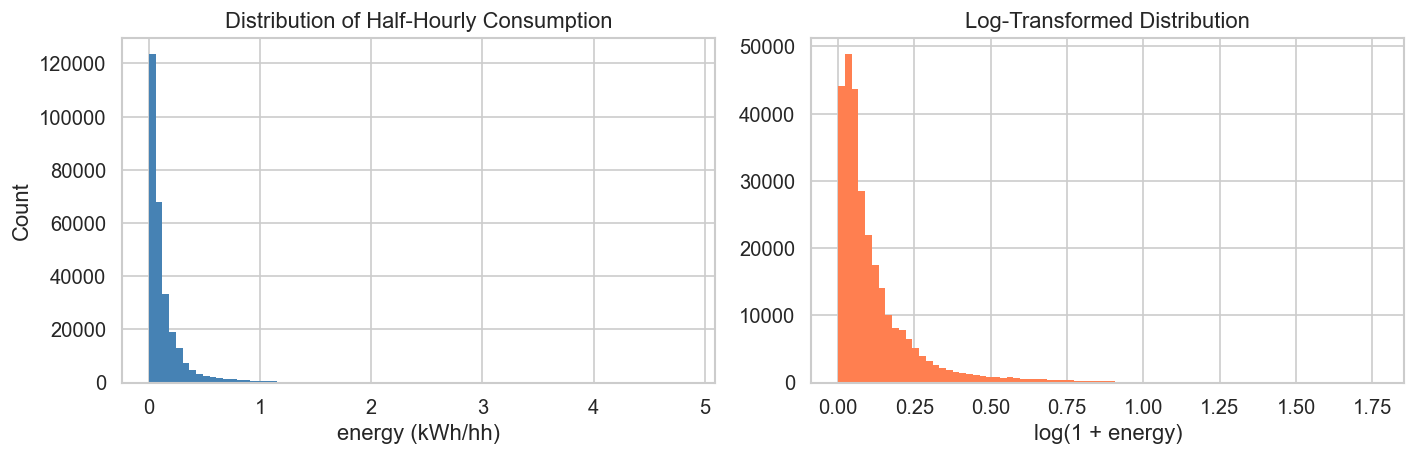

The distribution is right-skewed; most readings are low with occasional peaks.


In [13]:
# ── 10.2  Target distribution ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(hh["energy(kWh/hh)"], bins=80, color="steelblue", edgecolor="none")
axes[0].set_xlabel("energy (kWh/hh)")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of Half-Hourly Consumption")

axes[1].hist(np.log1p(hh["energy(kWh/hh)"]), bins=80, color="coral", edgecolor="none")
axes[1].set_xlabel("log(1 + energy)")
axes[1].set_title("Log-Transformed Distribution")

plt.tight_layout()
plt.savefig("eda_target_distribution.png", dpi=150)
plt.show()
print("The distribution is right-skewed; most readings are low with occasional peaks.")

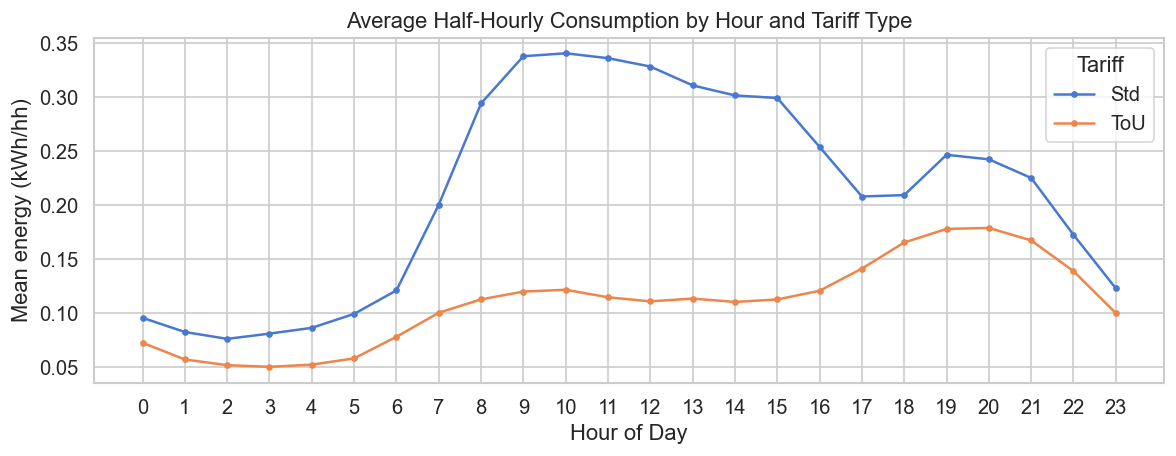

Clear morning (07–09h) and evening (17–21h) peaks. ToU customers may shift load away from peaks.


In [14]:
# ── 10.3  Diurnal load profile by tariff ─────────────────────────────────────
# Reconstruct a readable tariff label from the one-hot dummy
tou_dummy = [c for c in hh.columns if c.startswith("stdorToU_")]
if tou_dummy:
    hh["tariff"] = np.where(hh[tou_dummy[0]] == 1, "ToU", "Std")
else:
    hh["tariff"] = "Std"

diurnal = (
    hh.groupby(["hour", "tariff"])["energy(kWh/hh)"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 4))
for tariff, grp in diurnal.groupby("tariff"):
    ax.plot(grp["hour"], grp["energy(kWh/hh)"], marker="o", markersize=3, label=tariff)
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Mean energy (kWh/hh)")
ax.set_title("Average Half-Hourly Consumption by Hour and Tariff Type")
ax.set_xticks(range(0, 24))
ax.legend(title="Tariff")
plt.tight_layout()
plt.savefig("eda_diurnal_tariff.png", dpi=150)
plt.show()
print("Clear morning (07–09h) and evening (17–21h) peaks. ToU customers may shift load away from peaks.")

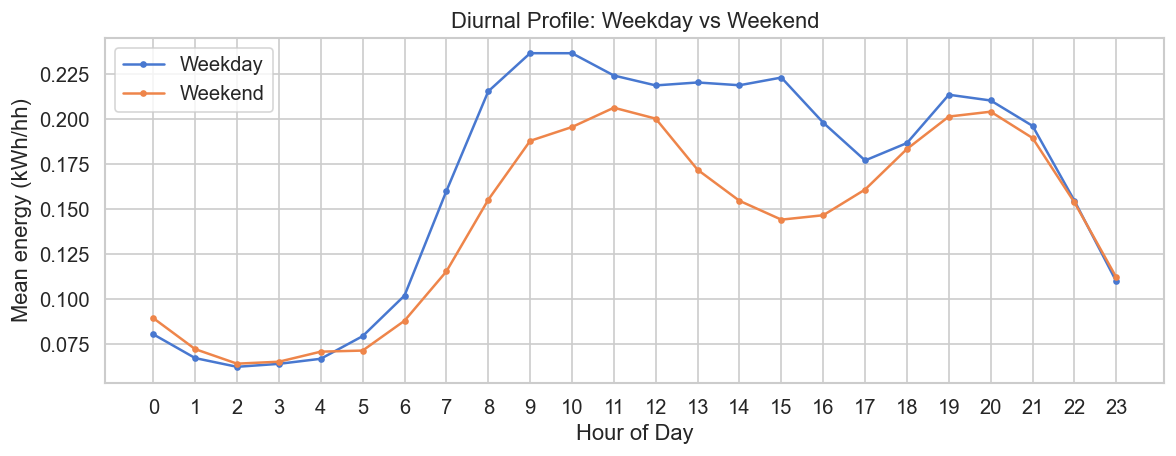

Weekdays show sharper morning peaks; weekends show later rise and flatter midday pattern.


In [15]:
# ── 10.4  Weekday vs Weekend load profile ─────────────────────────────────────
hh["day_type"] = hh["is_weekend"].map({0: "Weekday", 1: "Weekend"})

wknd = (
    hh.groupby(["hour", "day_type"])["energy(kWh/hh)"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 4))
for dtype, grp in wknd.groupby("day_type"):
    ax.plot(grp["hour"], grp["energy(kWh/hh)"], marker="o", markersize=3, label=dtype)
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Mean energy (kWh/hh)")
ax.set_title("Diurnal Profile: Weekday vs Weekend")
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.savefig("eda_weekend_profile.png", dpi=150)
plt.show()
print("Weekdays show sharper morning peaks; weekends show later rise and flatter midday pattern.")

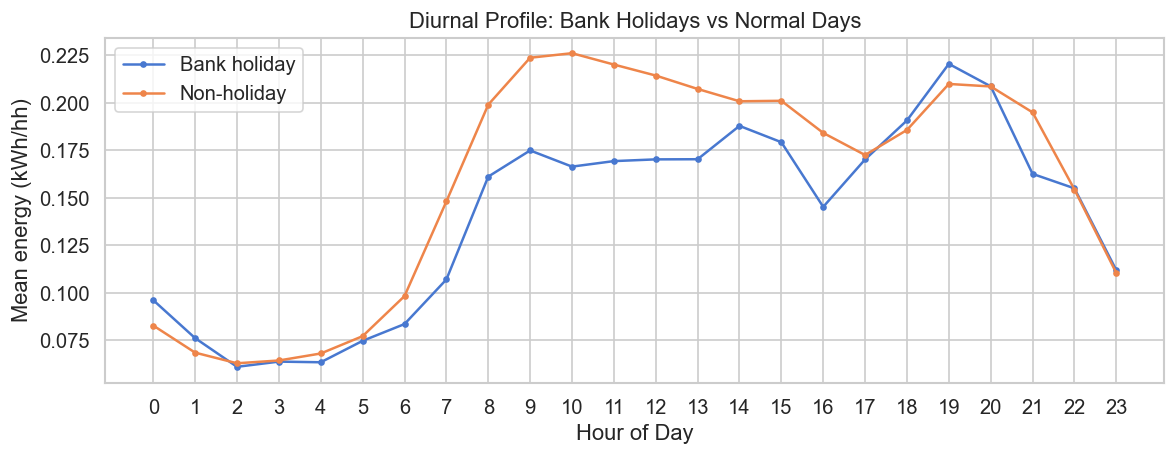

In [16]:
# ── 10.5  Holiday vs Non-Holiday ─────────────────────────────────────────────
hh["hol_label"] = hh["is_holiday"].map({0: "Non-holiday", 1: "Bank holiday"})

hol_profile = (
    hh.groupby(["hour", "hol_label"])["energy(kWh/hh)"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 4))
for label, grp in hol_profile.groupby("hol_label"):
    ax.plot(grp["hour"], grp["energy(kWh/hh)"], marker="o", markersize=3, label=label)
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Mean energy (kWh/hh)")
ax.set_title("Diurnal Profile: Bank Holidays vs Normal Days")
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.savefig("eda_holiday_profile.png", dpi=150)
plt.show()

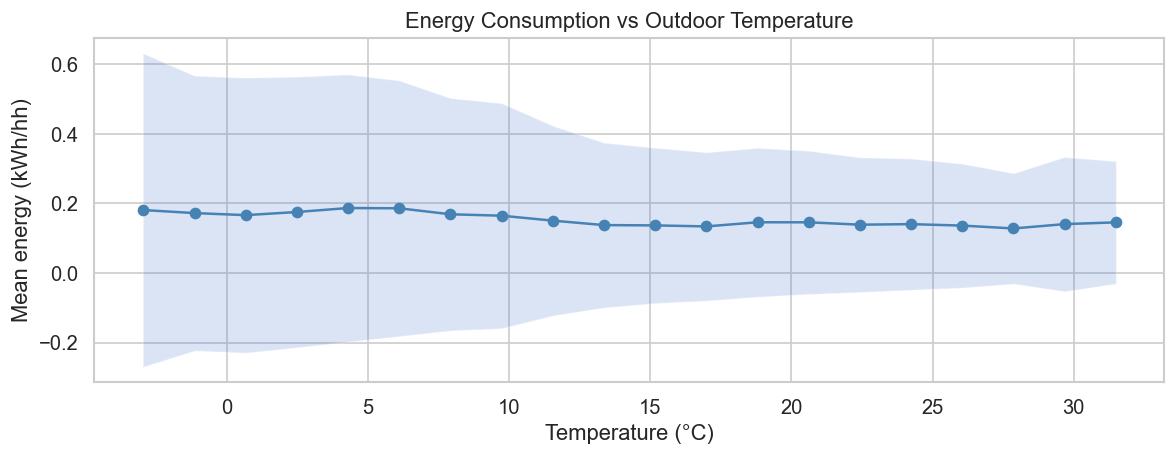

Higher consumption at lower temperatures reflects heating demand – justifies including temperature as a feature.


In [17]:
# ── 10.6  Temperature vs Consumption ─────────────────────────────────────────
# Bin temperature and compute mean consumption per bin
hh["temp_bin"] = pd.cut(hh["temperature"], bins=20)
temp_profile = (
    hh.groupby("temp_bin", observed=True)["energy(kWh/hh)"]
    .agg(["mean", "std"])
    .reset_index()
)
temp_profile["temp_mid"] = temp_profile["temp_bin"].apply(lambda x: x.mid).astype(float)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(temp_profile["temp_mid"], temp_profile["mean"], color="steelblue", marker="o")
ax.fill_between(
    temp_profile["temp_mid"],
    temp_profile["mean"] - temp_profile["std"],
    temp_profile["mean"] + temp_profile["std"],
    alpha=0.2,
)
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Mean energy (kWh/hh)")
ax.set_title("Energy Consumption vs Outdoor Temperature")
plt.tight_layout()
plt.savefig("eda_temperature.png", dpi=150)
plt.show()
print("Higher consumption at lower temperatures reflects heating demand – justifies including temperature as a feature.")

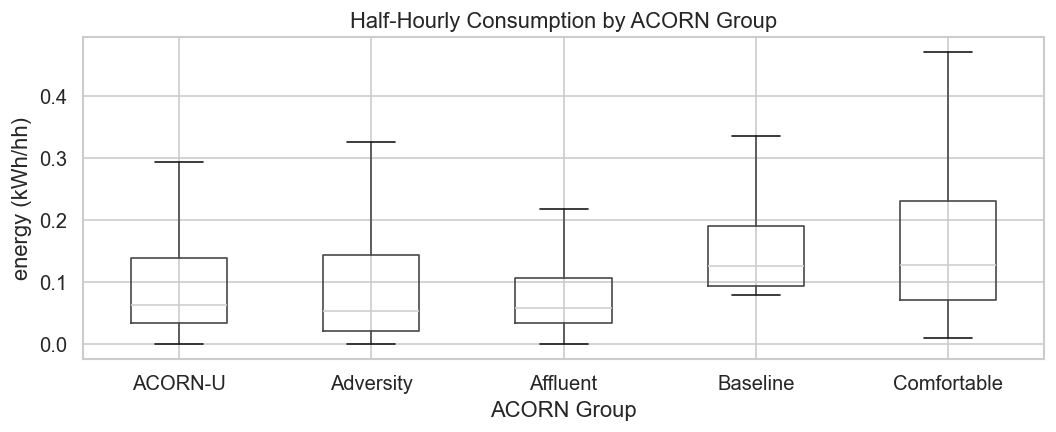

In [19]:
acorn_dummies = [c for c in hh.columns if c.startswith("Acorn_grouped_")]

def reconstruct_acorn(row):
    for col in acorn_dummies:
        if row[col] == 1:
            return col.replace("Acorn_grouped_", "")
    return "Baseline"  # if you used drop_first=True

if acorn_dummies:
    hh["acorn_label"] = hh.apply(reconstruct_acorn, axis=1)
else:
    hh["acorn_label"] = "Unknown"

fig, ax = plt.subplots(figsize=(9, 4))

hh.boxplot(
    column="energy(kWh/hh)",
    by="acorn_label",
    ax=ax,
    showfliers=False
)

ax.set_xlabel("ACORN Group")
ax.set_ylabel("energy (kWh/hh)")
ax.set_title("Half-Hourly Consumption by ACORN Group")
plt.suptitle("")
plt.tight_layout()
plt.savefig("eda_acorn.png", dpi=150)
plt.show()

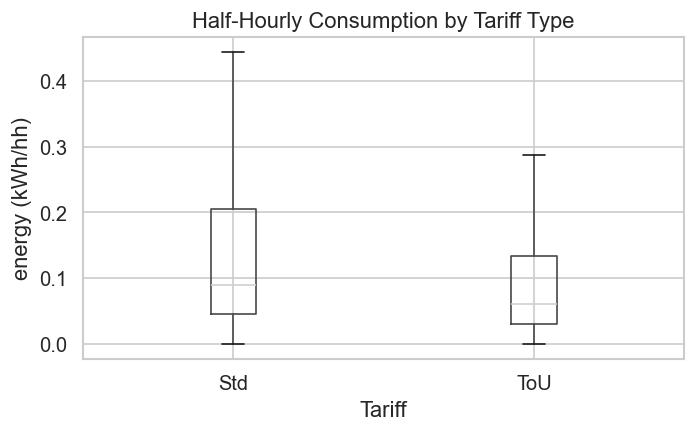

In [20]:
# ── 10.8  Consumption by Tariff ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 4))
hh.boxplot(column="energy(kWh/hh)", by="tariff", ax=ax, showfliers=False)
ax.set_xlabel("Tariff")
ax.set_ylabel("energy (kWh/hh)")
ax.set_title("Half-Hourly Consumption by Tariff Type")
plt.suptitle("")
plt.tight_layout()
plt.savefig("eda_tariff.png", dpi=150)
plt.show()

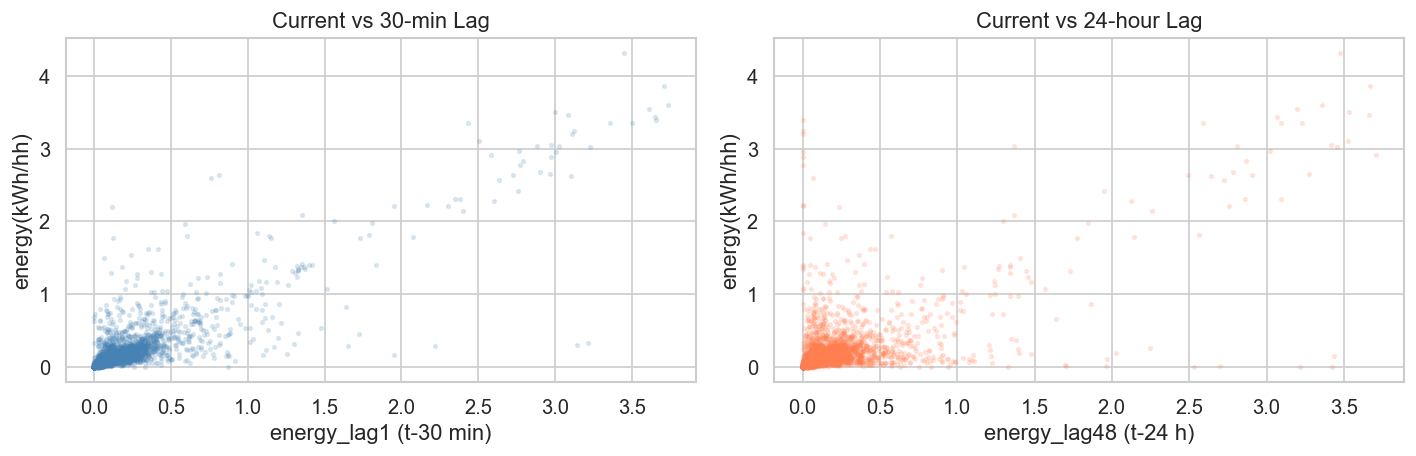

Strong linear relationship with lag1 confirms high short-term autocorrelation.


In [21]:
# ── 10.9  Autocorrelation / Lag relevance ─────────────────────────────────────
sample_hh = hh.sample(min(5000, len(hh)), random_state=RNG_SEED)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(sample_hh["energy_lag1"], sample_hh["energy(kWh/hh)"],
                alpha=0.15, s=5, color="steelblue")
axes[0].set_xlabel("energy_lag1 (t-30 min)")
axes[0].set_ylabel("energy(kWh/hh)")
axes[0].set_title("Current vs 30-min Lag")

axes[1].scatter(sample_hh["energy_lag48"], sample_hh["energy(kWh/hh)"],
                alpha=0.15, s=5, color="coral")
axes[1].set_xlabel("energy_lag48 (t-24 h)")
axes[1].set_ylabel("energy(kWh/hh)")
axes[1].set_title("Current vs 24-hour Lag")

plt.tight_layout()
plt.savefig("eda_lags.png", dpi=150)
plt.show()
print("Strong linear relationship with lag1 confirms high short-term autocorrelation.")

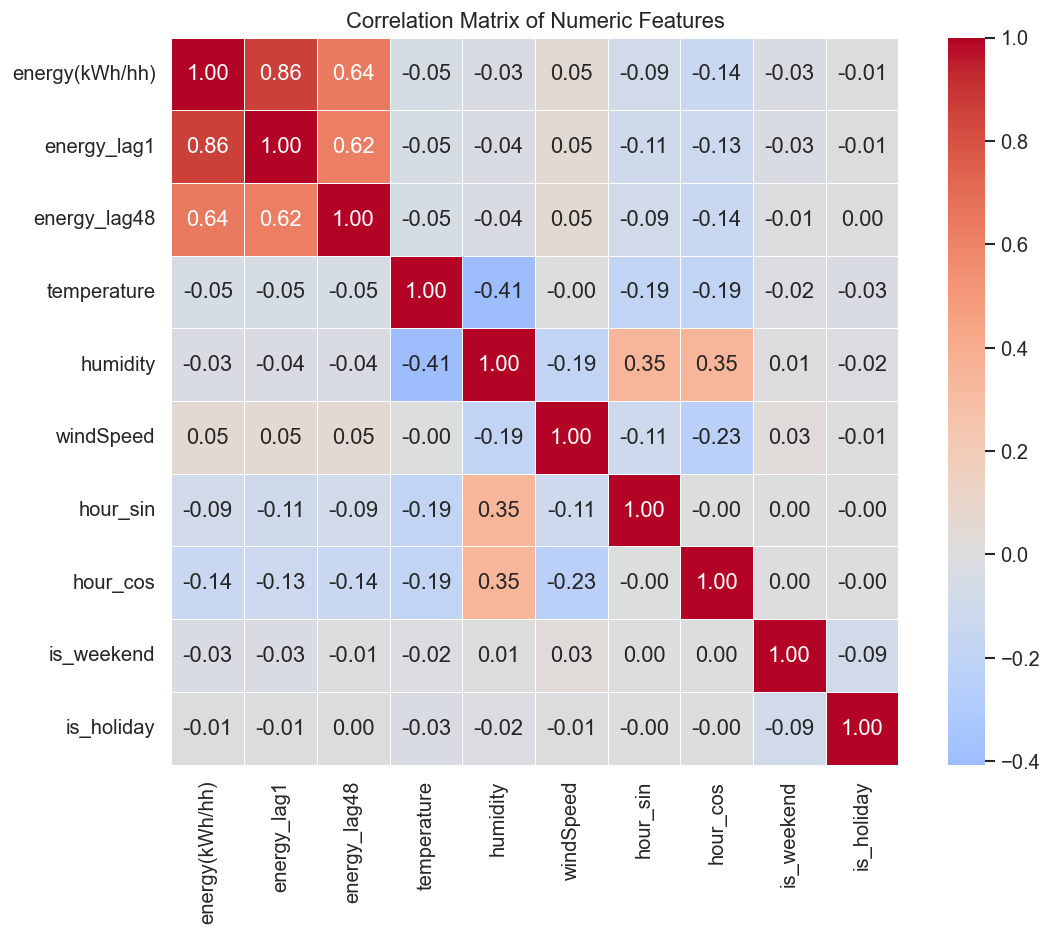

In [22]:
# ── 10.10  Correlation heatmap ────────────────────────────────────────────────
num_cols = [
    "energy(kWh/hh)", "energy_lag1", "energy_lag48",
    "temperature", "humidity", "windSpeed",
    "hour_sin", "hour_cos", "is_weekend", "is_holiday",
]
corr = hh[num_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, square=True, linewidths=0.5, ax=ax
)
ax.set_title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.savefig("eda_correlation.png", dpi=150)
plt.show()

### EDA Summary

| Observation | Implication for Modelling |
|---|---|
| Strong morning and evening peaks in all households | Include `hour_sin`, `hour_cos` |
| Weekend load curve is flatter and later | Include `is_weekend` |
| Bank holidays resemble weekends | Include `is_holiday` |
| Higher consumption at low temperatures | Include `temperature` |
| Affluent ACORN group consumes more on average | Include `Acorn_grouped` dummies |
| ToU households have slightly lower peaks | Include `stdorToU` dummy |
| `energy_lag1` is highly correlated with target | Include `energy_lag1` |
| `energy_lag48` shows clear daily periodicity | Include `energy_lag48` |